# WNMFDDA — Rejection Hypotheses R1, R2, R3 (Kaggle notebook)

Evidence-gathering notebook for the three **rejection statements** about *WNMFDDA* (Wang et al., J Transl Med 2022).
Every hypothesis follows the same **E / P / Q / V / L** framework:

| Part | Meaning |
|---|---|
| **E** | Equations and assumptions |
| **P** | Proposition (falsifiable claim) |
| **Q** | Quantifiable prediction + decision rule, fixed *before* running |
| **V** | Verification (reproducible code on Fdataset and Cdataset) |
| **L** | Link to predictive consequences |

**Rejection statements tested**

* **R1** – WKNN reconstruction and graph regularization may exploit overlapping similarity information, so their combination may add little beyond each component alone.
* **R2** – The graph-regularized low-rank factorization stage may add limited predictive value beyond WKNN-only or simple ranking baselines.
* **R3** – The graph-smoothness assumption may not match the association data, so graph regularization may oversmooth.

**How to run on Kaggle**
1. Add the `.mat` files of the official repo (`Fdataset.mat`, `Cdataset.mat`; https://github.com/meinengwang/WNMFDDA) as a Kaggle Dataset (*Add Data → Upload*), **or** turn Internet on so the notebook can `git clone` the repo.
2. Choose `PROFILE` in the config cell: `smoke` (minutes, sanity check) → `quick` (default) → `full` (20 seeds × 10 folds, several hours; results are checkpointed to CSV so a restarted session resumes).
3. Run all cells top to bottom. CPU is enough.

**Protocol (shared validity audit)** – 10-fold-style CV over known positives; held-out positives are removed from `Y` *before* WKNN; negatives are *all unobserved pairs* (not verified negatives); all methods share identical folds/candidates; no hyper-parameter tuning on test folds (paper parameters are fixed); paired statistics over seeds; Holm correction over the 6 primary tests (3 hypotheses × 2 datasets); practical-equivalence margin δ = 0.01 ROC-AUC.

**Documented deviations from the MATLAB source** – graph weights follow the *published* equation (the undefined `Clu_mat` in `Graph.m` is not invented); WKNN keeps the original *unweighted* denominator (Σ of selected similarities) and decay weights only in the numerator; WKNN neighbours are restricted to entities with ≥ 1 known association (paper text).

In [16]:

import os, sys, time, glob, subprocess, warnings, itertools
import numpy as np, pandas as pd
import scipy.io as sio, scipy.sparse as sps
from scipy import stats
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)

try:
    from IPython.display import display
except Exception:
    display = print

# ------------------------------ CONFIG ------------------------------
PROFILE = os.environ.get("WNMFDDA_PROFILE", "quick")

PROFILES = {
    "smoke": dict(N_SEEDS=2, N_FOLDS=3, MAX_ITER=30,
                  N_SENS_SEEDS=2, N_PERM=100),
    "quick": dict(N_SEEDS=5, N_FOLDS=5, MAX_ITER=150,
                  N_SENS_SEEDS=3, N_PERM=1000),
    "full": dict(N_SEEDS=20, N_FOLDS=10, MAX_ITER=300,
                 N_SENS_SEEDS=5, N_PERM=5000),
}

if PROFILE not in PROFILES:
    raise ValueError(f"Invalid PROFILE={PROFILE!r}. Use smoke, quick, or full.")

globals().update(PROFILES[PROFILE])

SEEDS = list(range(N_SEEDS))
SENS_SEEDS = SEEDS[:N_SENS_SEEDS]

PAPER = dict(p=5, K=5, a=0.5, k=160, lam=1.0, beta=0.02)
DELTA = 0.01
ALPHA = 0.05
NEG_RATIO = 1
TOPKS = (10, 20)
TOL = 1e-5

# ------------------------------ DATASET PATHS ------------------------------
DATA_DIR = "/kaggle/input/datasets/cliffbooth/drug-disease-association"

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(f"Kaggle dataset directory not found: {DATA_DIR}")

SEARCH_DIRS = [DATA_DIR]
ALLOW_GIT_CLONE = False  # Both .mat files are already available locally.

DATASETS = {
    "Fdataset": dict(keyword="dataf", expect=(593, 313, 1933)),
    "Cdataset": dict(keyword="datac", expect=(663, 409, 2532)),
}

# ------------------------------ OUTPUT / CACHE ------------------------------
OUT_DIR = "/kaggle/working"
os.makedirs(OUT_DIR, exist_ok=True)

RES_PATH = os.path.join(
    OUT_DIR, f"wnmfdda_rejection_results_{PROFILE}.csv"
)

FORCE_RERUN = False
RES = (
    pd.read_csv(RES_PATH)
    if os.path.exists(RES_PATH) and not FORCE_RERUN
    else pd.DataFrame()
)

PRIMARY, VERDICT, DETAIL = {}, {}, {}

print(
    f"PROFILE={PROFILE} | seeds={N_SEEDS} | folds={N_FOLDS} "
    f"| max_iter={MAX_ITER} | permutations={N_PERM}"
)
print(f"Dataset directory: {DATA_DIR}")
print(f"Cached result rows: {len(RES)} -> {RES_PATH}")


PROFILE=quick | seeds=5 | folds=5 | max_iter=150 | permutations=1000
Dataset directory: /kaggle/input/datasets/cliffbooth/drug-disease-association
Cached result rows: 0 -> /kaggle/working/wnmfdda_rejection_results_quick.csv


In [17]:

# ------------------------------ DATA LOADING ------------------------------

def find_mat(keyword):
    candidates = glob.glob(
        os.path.join(DATA_DIR, "**", "*.mat"),
        recursive=True
    )
    return sorted(
        path for path in set(candidates)
        if keyword.lower() in os.path.basename(path).lower()
    )


def read_mat_arrays(path):
    out = {}

    try:
        mat = sio.loadmat(path)

        for key, value in mat.items():
            if key.startswith("__"):
                continue

            if sps.issparse(value):
                value = value.toarray()

            if (
                isinstance(value, np.ndarray)
                and value.ndim == 2
                and np.issubdtype(value.dtype, np.number)
            ):
                out[key] = np.asarray(value, dtype=float)

    except NotImplementedError:
        # MATLAB v7.3 files use HDF5.
        import h5py

        with h5py.File(path, "r") as f:
            for key in f.keys():
                value = np.array(f[key])

                if (
                    value.ndim == 2
                    and np.issubdtype(value.dtype, np.number)
                ):
                    out[key] = value.T.astype(float)

    return out


def neighbor_order(S):
    S2 = np.array(S, dtype=float, copy=True)
    np.fill_diagonal(S2, -np.inf)

    # Exclude self and return neighbors in descending similarity order.
    return np.argsort(-S2, axis=1, kind="stable")[:, :-1]


def build_graph(S, p):
    # Published graph rule:
    # W=1 for mutual p-NN, W=0 if neither selects the other,
    # W=0.5 otherwise; S* = S elementwise-multiplied by W.

    n = S.shape[0]

    if not 1 <= p < n:
        raise ValueError(f"Invalid p={p} for graph with {n} nodes.")

    order = neighbor_order(S)

    N = np.zeros((n, n), dtype=bool)
    N[np.arange(n)[:, None], order[:, :p]] = True

    mutual = N & N.T
    neither = ~(N | N.T)

    Wm = np.where(
        mutual, 1.0,
        np.where(neither, 0.0, 0.5)
    )
    np.fill_diagonal(Wm, 0.0)

    Sg = S * Wm
    np.fill_diagonal(Sg, 0.0)

    return Sg, N


def load_dataset(name, spec):
    hits = find_mat(spec["keyword"])

    if len(hits) == 0:
        all_mat = glob.glob(
            os.path.join(DATA_DIR, "**", "*.mat"),
            recursive=True
        )
        raise FileNotFoundError(
            f"No .mat file matched keyword {spec['keyword']!r} "
            f"for {name}.\nAvailable files: {all_mat}"
        )

    if len(hits) > 1:
        raise RuntimeError(
            f"Multiple .mat files matched {name}: {hits}. "
            "Please specify the exact file."
        )

    path = hits[0]
    print(f"\n[{name}] Loading {path}")

    arrs = read_mat_arrays(path)

    # Retain sufficiently large numeric 2D matrices.
    big = {
        key: value for key, value in arrs.items()
        if min(value.shape) >= 50
    }

    rect = [
        key for key, value in big.items()
        if value.shape[0] != value.shape[1]
    ]

    sq = {
        key: value for key, value in big.items()
        if value.shape[0] == value.shape[1]
    }

    # Find the binary association matrix.
    y_candidates = [
        key for key in rect
        if np.all(np.isin(np.unique(big[key]), [0.0, 1.0]))
    ]

    if len(y_candidates) != 1:
        raise ValueError(
            f"Expected exactly one binary rectangular association "
            f"matrix in {path}; found {y_candidates}. "
            f"Available matrix shapes: "
            f"{ {k: v.shape for k, v in big.items()} }"
        )

    Y0 = big[y_candidates[0]]

    expected_n, expected_m, expected_pos = spec["expect"]

    # Select similarity matrices by their expected dimensions.
    drug_size = expected_n
    disease_size = expected_m

    def choose_similarity(size, preferred_name):
        candidates = [
            key for key, value in sq.items()
            if value.shape == (size, size)
        ]

        if not candidates:
            raise ValueError(
                f"No {size}x{size} similarity matrix found in {path}. "
                f"Available square matrices: "
                f"{ {k: v.shape for k, v in sq.items()} }"
            )

        preferred = [
            key for key in candidates
            if preferred_name in key.lower()
        ]

        if len(preferred) == 1:
            return preferred[0]

        if len(candidates) == 1:
            return candidates[0]

        raise ValueError(
            f"Ambiguous {preferred_name} similarity matrices: "
            f"{candidates}. Inspect the MAT variable names and "
            "select the intended matrix explicitly."
        )

    sr_key = choose_similarity(drug_size, "drug")
    sd_key = choose_similarity(disease_size, "disease")

    # Convert Y to drug x disease orientation.
    if Y0.shape == (drug_size, disease_size):
        Y = Y0.copy()
    elif Y0.shape == (disease_size, drug_size):
        Y = Y0.T.copy()
    else:
        raise ValueError(
            f"Unexpected association matrix shape {Y0.shape}; "
            f"expected {(drug_size, disease_size)} or "
            f"{(disease_size, drug_size)}."
        )

    SR = np.asarray(sq[sr_key], dtype=float).copy()
    SD = np.asarray(sq[sd_key], dtype=float).copy()

    # Validate and sanitize similarities.
    for label, S in [("SR", SR), ("SD", SD)]:
        if not np.isfinite(S).all():
            raise ValueError(
                f"{label} contains NaN/Inf values in {path}; "
                "inspect the source matrix before continuing."
            )

        if np.min(S) < -1e-10:
            raise ValueError(
                f"{label} contains negative similarities in {path}."
            )

    asym = max(
        np.abs(SR - SR.T).max(),
        np.abs(SD - SD.T).max()
    )

    # Symmetrization is explicit; report the discrepancy above.
    SR = (SR + SR.T) / 2
    SD = (SD + SD.T) / 2

    # Confirm binary labels rather than silently changing arbitrary values.
    if not np.all(np.isin(np.unique(Y), [0.0, 1.0])):
        raise ValueError("Association matrix is not binary.")

    actual_pos = int(Y.sum())

    if Y.shape != (expected_n, expected_m) or actual_pos != expected_pos:
        raise ValueError(
            f"{name} does not match expected dataset statistics. "
            f"Observed shape={Y.shape}, positives={actual_pos}; "
            f"expected shape={(expected_n, expected_m)}, "
            f"positives={expected_pos}."
        )

    D = type("Data", (), {})()
    D.name, D.Y, D.SR, D.SD = name, Y, SR, SD
    D.n, D.m = Y.shape

    D.ordR = neighbor_order(SR)
    D.ordD = neighbor_order(SD)

    D.SgR, D.NR = build_graph(SR, PAPER["p"])
    D.SgD, D.ND = build_graph(SD, PAPER["p"])

    D.neg_flat = np.flatnonzero(Y.ravel() == 0)

    print(
        f"  Y shape={Y.shape}, positives={actual_pos}, "
        f"density={Y.mean():.6f}"
    )
    print(f"  Similarity variables: SR={sr_key}, SD={sd_key}")
    print(f"  Max similarity asymmetry before symmetrizing: {asym:.3e}")

    return D


LOADED = {
    name: load_dataset(name, spec)
    for name, spec in DATASETS.items()
}

print("\nBoth datasets loaded successfully.")



[Fdataset] Loading /kaggle/input/datasets/cliffbooth/drug-disease-association/DataF.mat
  Y shape=(593, 313), positives=1933, density=0.010414
  Similarity variables: SR=SR, SD=SD
  Max similarity asymmetry before symmetrizing: 0.000e+00

[Cdataset] Loading /kaggle/input/datasets/cliffbooth/drug-disease-association/DataC.mat
  Y shape=(663, 409), positives=2532, density=0.009337
  Similarity variables: SR=SR, SD=SD
  Max similarity asymmetry before symmetrizing: 0.000e+00

Both datasets loaded successfully.


In [18]:
# ------------------------------ CORE MODEL (faithful to the paper's equations) ------------------------------
def wknn_side(S, P, K, a, order, eps=1e-12):
    # P: entities x features (rows are profiles). numerator uses decay a^(t-1)*S, denominator is the UNWEIGHTED sum of selected S
    n = S.shape[0]
    valid = (P.sum(axis=1) > 0)[order]                  # neighbours must have >= 1 known association
    cum = np.cumsum(valid, axis=1)
    sel = valid & (cum <= K)
    rows = np.arange(n)[:, None]
    sims = S[rows, order]
    w = np.where(sel, np.power(a, np.maximum(cum - 1, 0)) * sims, 0.0)
    den = np.where(sel, sims, 0.0).sum(axis=1)
    Wfull = np.zeros((n, n)); Wfull[rows, order] = w
    out = Wfull @ P
    ok = den > eps
    out[ok] /= den[ok, None]; out[~ok] = 0.0
    return out

def wknn_reconstruct(Y, D, K=PAPER["K"], a=PAPER["a"]):
    Yr = wknn_side(D.SR, Y, K, a, D.ordR)
    Yd = wknn_side(D.SD, Y.T, K, a, D.ordD).T
    Yrd = (Yr + Yd) / 2
    return np.maximum(Y, Yrd), Yrd

def selected_neighbors(P, K, order):
    n = order.shape[0]
    valid = (P.sum(axis=1) > 0)[order]
    cum = np.cumsum(valid, axis=1)
    out = np.zeros((n, n), bool); out[np.arange(n)[:, None], order] = valid & (cum <= K)
    return out

def objective(M, A, B, SgR, SgD, lam, beta):
    rec = (M ** 2).sum() - 2 * (B * (A @ M)).sum() + ((A @ A.T) * (B @ B.T)).sum()
    dR, dD = SgR.sum(1), SgD.sum(1)
    trA = (A * (A * dR[None, :] - A @ SgR)).sum()          # Tr(A L A^T)
    trB = (B * (B * dD[None, :] - B @ SgD)).sum()          # Tr(B L_D B^T)
    return rec + lam * (trA + trB) + beta * ((A ** 2).sum() + (B ** 2).sum())

def nmf_fit(M, SgR, SgD, k, lam, beta, max_iter, tol=TOL, seed=0, check_every=10, eps=1e-12):
    # multiplicative updates, paper Eq. (21)-(22);  A: k x n, B: k x m
    rng = np.random.default_rng(seed)
    n, m = M.shape
    c = 2 * np.sqrt(max(M.mean(), 1e-8) / k)
    A = rng.random((k, n)) * c + 1e-6; B = rng.random((k, m)) * c + 1e-6
    dR, dD = SgR.sum(1)[None, :], SgD.sum(1)[None, :]
    prev, obj = None, np.nan
    for it in range(1, max_iter + 1):
        A *= (B @ M.T + lam * (A @ SgR)) / (beta * A + lam * A * dR + (B @ B.T) @ A + eps)
        B *= (A @ M + lam * (B @ SgD)) / (beta * B + lam * B * dD + (A @ A.T) @ B + eps)
        if it % check_every == 0 or it == max_iter:
            obj = objective(M, A, B, SgR, SgD, lam, beta)
            if prev is not None and abs(prev - obj) / max(abs(prev), eps) < tol:
                break
            prev = obj
    return A, B, it, obj

def make_split(D, seed, fold, n_folds=None):
    n_folds = n_folds or N_FOLDS
    pos = np.argwhere(D.Y > 0)
    perm = np.random.default_rng(seed).permutation(len(pos))
    test = pos[np.array_split(perm, n_folds)[fold]]
    Ytr = D.Y.copy(); Ytr[test[:, 0], test[:, 1]] = 0.0        # held-out positives removed BEFORE any label-based step
    rng2 = np.random.default_rng([seed, fold, 12345])
    neg_bal = rng2.choice(D.neg_flat, size=len(test) * NEG_RATIO, replace=False)
    sp = type("Split", (), {})(); sp.test, sp.Ytr, sp.neg_bal = test, Ytr, neg_bal
    return sp

def evaluate(Sc, D, sp, topks=TOPKS):
    ti, tj = sp.test[:, 0], sp.test[:, 1]
    ps = Sc[ti, tj]; ns = Sc.ravel()[D.neg_flat]
    y = np.r_[np.ones(len(ps)), np.zeros(len(ns))]; s = np.r_[ps, ns]
    out = dict(auc=roc_auc_score(y, s), aupr=average_precision_score(y, s))
    nb = Sc.ravel()[sp.neg_bal]
    out["aupr_bal"] = average_precision_score(np.r_[np.ones(len(ps)), np.zeros(len(nb))], np.r_[ps, nb])
    Sm = Sc[ti].copy(); Sm[sp.Ytr[ti] > 0] = -np.inf             # candidates = all non-training pairs of that drug
    rank = (Sm > ps[:, None]).sum(1) + ((Sm == ps[:, None]).sum(1) - 1) / 2.0
    for k in topks:
        out[f"rec{k}"] = float((rank < k).mean())
    return out

def score_cond(c, D, sp, seed, fold):
    kind = c["kind"]
    if kind == "pop":                                            # association-popularity baseline: deg(drug) * deg(disease)
        return np.outer(sp.Ytr.sum(1), sp.Ytr.sum(0)), 0, np.nan
    M = wknn_reconstruct(sp.Ytr, D)[0] if c["wknn"] else sp.Ytr
    if kind == "wknn":
        return M, 0, np.nan
    A, B, it, obj = nmf_fit(M, D.SgR, D.SgD, c["k"], c["lam"], PAPER["beta"], MAX_ITER, seed=1000 * seed + fold)
    return A.T @ B, it, obj

def run_grid(D, conds, seeds):
    global RES
    done = set(map(tuple, RES[["dataset", "cond", "seed", "fold"]].values.tolist())) if len(RES) else set()
    t0 = time.time(); added = 0
    for seed in seeds:
        rows = []
        for fold in range(N_FOLDS):
            todo = [c for c in conds if (D.name, c, int(seed), int(fold)) not in done]
            if not todo:
                continue
            sp = make_split(D, seed, fold)
            for c in todo:
                t = time.perf_counter()
                Sc, it, obj = score_cond(conds[c], D, sp, seed, fold)
                el = time.perf_counter() - t
                rows.append(dict(dataset=D.name, cond=c, seed=seed, fold=fold, time_s=el, n_iter=it, obj=obj, **evaluate(Sc, D, sp)))
        if rows:
            RES = pd.concat([RES, pd.DataFrame(rows)], ignore_index=True); RES.to_csv(RES_PATH, index=False); added += len(rows)
            print(f"  [{D.name}] seed {seed} done ({added} new rows, {time.time()-t0:.0f}s)")
    return RES

# ------------------------------ STATISTICS ------------------------------
def paired_stats(d, delta=None, alpha=ALPHA, n_boot=5000, seed=0):
    d = np.asarray(d, float); d = d[np.isfinite(d)]; n = len(d)
    keys = ["n", "mean", "sd", "ci_lo", "ci_hi", "boot_lo", "boot_hi", "p", "dz", "min", "max", "p_tost"]
    o = {k: np.nan for k in keys}; o["n"] = n
    if n == 0:
        return o
    o["mean"], o["min"], o["max"] = d.mean(), d.min(), d.max()
    if n < 2:
        return o
    sd = d.std(ddof=1); se = sd / np.sqrt(n); tc = stats.t.ppf(1 - alpha / 2, n - 1)
    o.update(sd=sd, ci_lo=o["mean"] - tc * se, ci_hi=o["mean"] + tc * se, dz=o["mean"] / sd if sd > 0 else np.nan)
    o["p"] = 2 * stats.t.sf(abs(o["mean"] / se), n - 1) if se > 0 else (1.0 if o["mean"] == 0 else 0.0)
    bm = np.random.default_rng(seed).choice(d, size=(n_boot, n), replace=True).mean(1)
    o["boot_lo"], o["boot_hi"] = np.percentile(bm, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    if delta is not None:                                         # TOST: H0a diff <= -delta ; H0b diff >= +delta
        if se > 0:
            o["p_tost"] = max(stats.t.sf((o["mean"] + delta) / se, n - 1), stats.t.cdf((o["mean"] - delta) / se, n - 1))
        else:
            o["p_tost"] = 0.0 if abs(o["mean"]) < delta else 1.0
    return o

def advantage_verdict(st, delta=DELTA):
    # st describes an ADVANTAGE (candidate - reference). Rejection statement supported when the advantage is practically below delta.
    if not np.isfinite(st["ci_lo"]):
        return "INCONCLUSIVE (too few seeds)"
    if st["ci_hi"] < delta:
        return "SUPPORTED (advantage < delta)"
    if st["ci_lo"] > delta:
        return "WEAKENED (advantage > delta)"
    return "INCONCLUSIVE (CI straddles delta)"

def holm(p, m=None):
    p = np.nan_to_num(np.asarray(p, float), nan=1.0); m = m or len(p)
    order = np.argsort(p); adj = np.empty(len(p)); run = 0.0
    for r, i in enumerate(order):
        run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

def seedmeans(ds, metric, conds, seeds=None):
    df = RES[(RES.dataset == ds) & (RES.cond.isin(conds))]
    if seeds is not None:
        df = df[df.seed.isin(seeds)]
    return df.groupby(["seed", "cond"])[metric].mean().unstack("cond")[list(conds)].dropna()

def stat_row(label, d, delta=None):
    s = paired_stats(d, delta)
    r = {"contrast": label, "n_seeds": s["n"], "mean": s["mean"], "ci95_lo": s["ci_lo"], "ci95_hi": s["ci_hi"],
         "boot_lo": s["boot_lo"], "boot_hi": s["boot_hi"], "worst_seed": s["min"], "best_seed": s["max"], "p": s["p"]}
    if delta is not None:
        r["p_TOST"] = s["p_tost"]
    return r, s

CONDS = {
    "POP":       dict(kind="pop",  wknn=False, lam=0.0, k=0),
    "WKNN_ONLY": dict(kind="wknn", wknn=True,  lam=0.0, k=0),
    "W0G0": dict(kind="nmf", wknn=False, lam=0.0,           k=PAPER["k"]),
    "W1G0": dict(kind="nmf", wknn=True,  lam=0.0,           k=PAPER["k"]),
    "W0G1": dict(kind="nmf", wknn=False, lam=PAPER["lam"],  k=PAPER["k"]),
    "W1G1": dict(kind="nmf", wknn=True,  lam=PAPER["lam"],  k=PAPER["k"]),
    "W1G1_k10": dict(kind="nmf", wknn=True, lam=PAPER["lam"], k=10),
    "W1G1_k40": dict(kind="nmf", wknn=True, lam=PAPER["lam"], k=40),
}
LAMS = [0.0, 0.1, 1.0, 10.0]
def lam_name(w, lam):
    return f"W{w}G0" if lam == 0 else (f"W{w}G1" if lam == 1.0 else f"W{w}_lam{lam}")
for w in (0, 1):
    for lam in LAMS:
        CONDS.setdefault(lam_name(w, lam), dict(kind="nmf", wknn=bool(w), lam=lam, k=PAPER["k"]))
print("conditions defined:", list(CONDS))

conditions defined: ['POP', 'WKNN_ONLY', 'W0G0', 'W1G0', 'W0G1', 'W1G1', 'W1G1_k10', 'W1G1_k40', 'W0_lam0.1', 'W0_lam10.0', 'W1_lam0.1', 'W1_lam10.0']


In [19]:
# ------------------------------ SHARED VALIDITY AUDIT (prerequisite for R1-R3) ------------------------------
for ds, D in LOADED.items():
    sp = make_split(D, 0, 0); sp2 = make_split(D, 0, 0)
    ti, tj = sp.test[:, 0], sp.test[:, 1]
    assert (sp.Ytr[ti, tj] == 0).all(), "held-out positives still present in training matrix"
    assert (sp.Ytr <= D.Y).all() and int(D.Y.sum() - sp.Ytr.sum()) == len(sp.test)
    assert np.array_equal(sp.test, sp2.test) and np.array_equal(sp.neg_bal, sp2.neg_bal), "splits are not deterministic"
    assert not (D.Y[np.unravel_index(sp.neg_bal, D.Y.shape)] > 0).any(), "balanced negatives must be unobserved pairs"
    # positive control: a LEAKY pipeline (WKNN built from the full Y) must look better than the correct one
    good = evaluate(wknn_reconstruct(sp.Ytr, D)[0], D, sp)["auc"]
    leaky = evaluate(wknn_reconstruct(D.Y, D)[0], D, sp)["auc"]
    print(f"[{ds}] splits deterministic, train/test disjoint | WKNN-only AUC correct={good:.4f} vs leaky(full Y)={leaky:.4f} "
          f"-> leakage would inflate by {leaky-good:+.4f}")
    assert leaky > good
print("Audit passed. Negatives = ALL unobserved pairs (not verified negatives); same folds/candidates for every method; "
      "no hyper-parameter selection on test folds (paper parameters fixed).")

# runtime projection
D0 = LOADED["Fdataset"]; sp0 = make_split(D0, 0, 0); M0 = wknn_reconstruct(sp0.Ytr, D0)[0]
t = time.perf_counter(); nmf_fit(M0, D0.SgR, D0.SgD, PAPER["k"], PAPER["lam"], PAPER["beta"], MAX_ITER); t_fit = time.perf_counter() - t
n_fits = 2 * ((6 * N_SEEDS * N_FOLDS) + (4 * N_SENS_SEEDS * N_FOLDS))
print(f"one k=160 fit ≈ {t_fit:.1f}s ; about {n_fits} fits in total ≈ {n_fits*t_fit/60:.0f} min (+ evaluation overhead)")

[Fdataset] splits deterministic, train/test disjoint | WKNN-only AUC correct=0.7976 vs leaky(full Y)=1.0000 -> leakage would inflate by +0.2024
[Cdataset] splits deterministic, train/test disjoint | WKNN-only AUC correct=0.8397 vs leaky(full Y)=1.0000 -> leakage would inflate by +0.1603
Audit passed. Negatives = ALL unobserved pairs (not verified negatives); same folds/candidates for every method; no hyper-parameter selection on test folds (paper parameters fixed).
one k=160 fit ≈ 2.0s ; about 420 fits in total ≈ 14 min (+ evaluation overhead)


---
# R1 — WKNN reconstruction and graph regularization may overlap

> *WKNN reconstruction and graph regularization may exploit overlapping similarity information, so their combination may not provide a substantial additional predictive benefit over the contribution of each component individually.*

### E — Equations
WKNN: $Y^R_{i\ell}=\dfrac{\sum_{t=1}^{K}a^{t-1}S^R_{i,j_t}Y_{j_t\ell}}{\sum_{t=1}^{K}S^R_{i,j_t}}$, $\;Y'=\max\!\big(Y,\tfrac{Y^R+Y^D}{2}\big)$ — propagates **labels** through the top-$K$ neighbours.
Graph term: $\lambda\,[\operatorname{Tr}(AL_RA^\top)+\operatorname{Tr}(BL_DB^\top)]$ with $S^*=S\odot W$ built from the top-$p$ neighbours — propagates **latent factors** through (almost) the same neighbours. The operators differ ($K$ vs $p$, decay weights vs. mutual-neighbour weights) but draw on the same similarity matrices.

### P — Proposition
The full model is not necessarily better than either component alone; the marginal benefit and the interaction must be measured.

### Q — Quantifiable prediction (decision rule fixed in advance)
Factorial ablation (WKNN ∈ {off,on}) × (graph $\lambda$ ∈ {0, 1}) with identical folds and negatives. Paired (per-seed) contrasts on ROC-AUC (also AUPR, balanced AUPR, recall@10/20):
* interaction $=(W_1G_1-W_1G_0)-(W_0G_1-W_0G_0)$,
* **marginal gain of full model over the better single component**.

R1 is **SUPPORTED** if the 95 % CI of the marginal gain lies below $\delta=0.01$; **WEAKENED** if the CI lies above $\delta$; otherwise **INCONCLUSIVE**. Primary test for Holm: two-sided paired test of the AUC interaction.

### V — Verification
Cells below: (1) neighbour-set overlap between WKNN and graph, (2) factorial runs, (3) paired statistics.

### L — Link to predictive consequences
A small interaction/marginal gain supports overlap *in predictive contribution* (not identical information). A clearly positive interaction ≥ δ weakens R1.

In [20]:
# ---- V1: do WKNN and the graph use the same neighbours? (mechanistic overlap, labels = full Y; descriptive only)
rows = []
for ds, D in LOADED.items():
    for side, order, S, P, Ng in (("drug", D.ordR, D.SR, D.Y, D.NR), ("disease", D.ordD, D.SD, D.Y.T, D.ND)):
        A_ = selected_neighbors(P, PAPER["K"], order); B_ = Ng
        inter = (A_ & B_).sum(1); union = (A_ | B_).sum(1)
        rows.append(dict(dataset=ds, side=side, K=PAPER["K"], p=PAPER["p"],
                         mean_jaccard=np.mean(inter / np.maximum(union, 1)),
                         frac_WKNN_neighbours_also_in_graph_pNN=inter.sum() / A_.sum()))
display(pd.DataFrame(rows).round(3))

,dataset,side,K,p,mean_jaccard,frac_WKNN_neighbours_also_in_graph_pNN
0,Fdataset,drug,5,5,1.0,1.0
1,Fdataset,disease,5,5,1.0,1.0
2,Cdataset,drug,5,5,1.0,1.0
3,Cdataset,disease,5,5,1.0,1.0


Running R1 grid on Fdataset ...
  [Fdataset] seed 0 done (20 new rows, 47s)
  [Fdataset] seed 1 done (40 new rows, 95s)
  [Fdataset] seed 2 done (60 new rows, 142s)
  [Fdataset] seed 3 done (80 new rows, 189s)
  [Fdataset] seed 4 done (100 new rows, 236s)
Running R1 grid on Cdataset ...
  [Cdataset] seed 0 done (20 new rows, 62s)
  [Cdataset] seed 1 done (40 new rows, 128s)
  [Cdataset] seed 2 done (60 new rows, 195s)
  [Cdataset] seed 3 done (80 new rows, 260s)
  [Cdataset] seed 4 done (100 new rows, 323s)
R1 | Fdataset


,auc,aupr,aupr_bal,rec10,rec20
cond,,,,,
W0G0,0.8091,0.0812,0.8479,0.4949,0.6033
W1G0,0.8987,0.1521,0.9180,0.5709,0.6793
W0G1,0.9205,0.3060,0.9392,0.6903,0.7681
W1G1,0.9244,0.2823,0.9416,0.6727,0.7657



-- paired contrasts on auc (unit = seed mean over folds) --


,n_seeds,mean,ci95_lo,ci95_hi,boot_lo,boot_hi,worst_seed,best_seed,p
contrast,,,,,,,,,
WKNN alone (W1G0 - W0G0),5,0.0896,0.0850,0.0943,0.0869,0.0924,0.0846,0.0938,0.0000
Graph alone (W0G1 - W0G0),5,0.1114,0.1070,0.1158,0.1087,0.1141,0.1080,0.1160,0.0000
Combined (W1G1 - W0G0),5,0.1154,0.1101,0.1206,0.1121,0.1186,0.1109,0.1212,0.0000
WKNN given graph on (W1G1 - W0G1),5,0.0040,0.0028,0.0052,0.0032,0.0047,0.0029,0.0052,0.0007
Graph given WKNN on (W1G1 - W1G0),5,0.0257,0.0231,0.0283,0.0240,0.0272,0.0225,0.0277,0.0000
INTERACTION,5,-0.0857,-0.0899,-0.0815,-0.0880,-0.0830,-0.0886,-0.0803,0.0000
Full minus best single (W0G1),5,0.0040,0.0028,0.0052,0.0032,0.0047,0.0029,0.0052,0.0007



-- paired contrasts on aupr (unit = seed mean over folds) --


,n_seeds,mean,ci95_lo,ci95_hi,boot_lo,boot_hi,worst_seed,best_seed,p
contrast,,,,,,,,,
WKNN alone (W1G0 - W0G0),5,0.0709,0.0646,0.0772,0.0675,0.0751,0.0659,0.0791,0.0000
Graph alone (W0G1 - W0G0),5,0.2248,0.2193,0.2303,0.2215,0.2284,0.2202,0.2310,0.0000
Combined (W1G1 - W0G0),5,0.2011,0.1946,0.2076,0.1971,0.2052,0.1949,0.2080,0.0000
WKNN given graph on (W1G1 - W0G1),5,-0.0238,-0.0295,-0.0180,-0.0273,-0.0202,-0.0302,-0.0175,0.0003
Graph given WKNN on (W1G1 - W1G0),5,0.1302,0.1184,0.1419,0.1221,0.1372,0.1158,0.1420,0.0000
INTERACTION,5,-0.0947,-0.1029,-0.0865,-0.1000,-0.0898,-0.1045,-0.0888,0.0000
Full minus best single (W0G1),5,-0.0238,-0.0295,-0.0180,-0.0273,-0.0202,-0.0302,-0.0175,0.0003


... (15 outputs left out)

,n_seeds,mean,ci95_lo,ci95_hi,boot_lo,boot_hi,worst_seed,best_seed,p
contrast,,,,,,,,,
WKNN alone (W1G0 - W0G0),5,0.109,0.0976,0.1204,0.1020,0.1158,0.0979,0.1173,0.0000
Graph alone (W0G1 - W0G0),5,0.202,0.1867,0.2173,0.1909,0.2089,0.1805,0.2113,0.0000
Combined (W1G1 - W0G0),5,0.186,0.1725,0.1995,0.1779,0.1939,0.1710,0.1994,0.0000
WKNN given graph on (W1G1 - W0G1),5,-0.016,-0.0240,-0.0079,-0.0216,-0.0116,-0.0265,-0.0095,0.0054
Graph given WKNN on (W1G1 - W1G0),5,0.077,0.0667,0.0873,0.0709,0.0831,0.0668,0.0881,0.0000
INTERACTION,5,-0.125,-0.1413,-0.1086,-0.1348,-0.1151,-0.1398,-0.1074,0.0000
Full minus best single (W0G1),5,-0.016,-0.0240,-0.0079,-0.0216,-0.0116,-0.0265,-0.0095,0.0054



-- paired contrasts on rec20 (unit = seed mean over folds) --


,n_seeds,mean,ci95_lo,ci95_hi,boot_lo,boot_hi,worst_seed,best_seed,p
contrast,,,,,,,,,
WKNN alone (W1G0 - W0G0),5,0.0927,0.0887,0.0968,0.0902,0.0953,0.0885,0.0964,0.0000
Graph alone (W0G1 - W0G0),5,0.1568,0.1530,0.1605,0.1547,0.1592,0.1540,0.1615,0.0000
Combined (W1G1 - W0G0),5,0.1521,0.1461,0.1580,0.1483,0.1558,0.1473,0.1576,0.0000
WKNN given graph on (W1G1 - W0G1),5,-0.0047,-0.0082,-0.0013,-0.0064,-0.0023,-0.0067,0.0000,0.0183
Graph given WKNN on (W1G1 - W1G0),5,0.0593,0.0515,0.0672,0.0549,0.0644,0.0533,0.0691,0.0000
INTERACTION,5,-0.0975,-0.1041,-0.0908,-0.1009,-0.0927,-0.1011,-0.0885,0.0000
Full minus best single (W0G1),5,-0.0047,-0.0082,-0.0013,-0.0064,-0.0023,-0.0067,0.0000,0.0183



R1 verdict [Cdataset]: SUPPORTED (advantage < delta)  |  interaction=-0.0802 CI[-0.0826,-0.0778]; full-vs-best-single(W0G1)=+0.0032 CI[+0.0023,+0.0041]


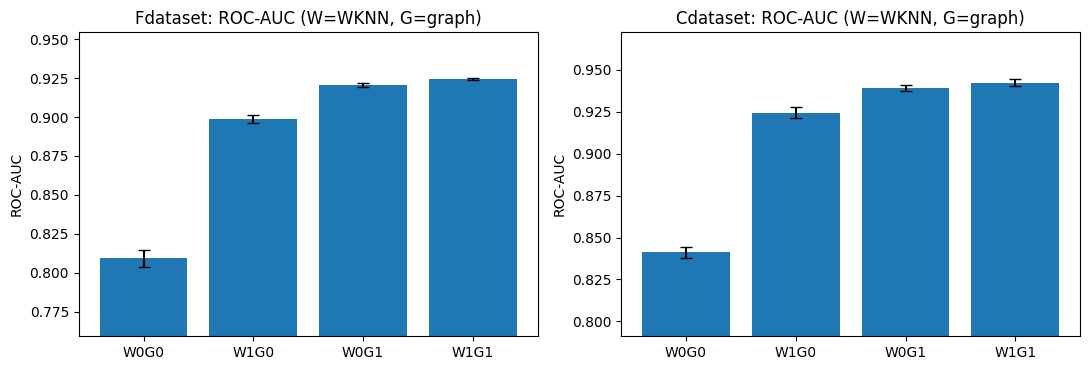

In [21]:
# ---- V2: factorial ablation (identical folds / negatives for all four cells) ----
R1_CONDS = {c: CONDS[c] for c in ["W0G0", "W1G0", "W0G1", "W1G1"]}
for ds, D in LOADED.items():
    print(f"Running R1 grid on {ds} ...")
    run_grid(D, R1_CONDS, SEEDS)

METRICS = ["auc", "aupr", "aupr_bal"] + [f"rec{k}" for k in TOPKS]

def r1_contrasts(T):
    best = "W1G0" if T["W1G0"].mean() >= T["W0G1"].mean() else "W0G1"
    return best, {
        "WKNN alone (W1G0 - W0G0)": T["W1G0"] - T["W0G0"],
        "Graph alone (W0G1 - W0G0)": T["W0G1"] - T["W0G0"],
        "Combined (W1G1 - W0G0)": T["W1G1"] - T["W0G0"],
        "WKNN given graph on (W1G1 - W0G1)": T["W1G1"] - T["W0G1"],
        "Graph given WKNN on (W1G1 - W1G0)": T["W1G1"] - T["W1G0"],
        "INTERACTION": T["W1G1"] - T["W1G0"] - T["W0G1"] + T["W0G0"],
        f"Full minus best single ({best})": T["W1G1"] - T[best],
    }

for ds in LOADED:
    print("=" * 100); print(f"R1 | {ds}")
    cell_means = pd.concat({m: seedmeans(ds, m, list(R1_CONDS)).mean() for m in METRICS}, axis=1)
    display(cell_means.round(4))
    for m in METRICS:
        T = seedmeans(ds, m, list(R1_CONDS))
        best, eff = r1_contrasts(T)
        tab = pd.DataFrame([stat_row(k, v)[0] for k, v in eff.items()]).set_index("contrast")
        print(f"\n-- paired contrasts on {m} (unit = seed mean over folds) --"); display(tab.round(4))
        if m == "auc":
            inter = stat_row("INTERACTION", eff["INTERACTION"])[1]
            gain = stat_row("gain", eff[f"Full minus best single ({best})"])[1]
            PRIMARY[("R1", ds)] = dict(test="paired t: AUC interaction != 0", stat=inter["mean"], p=inter["p"],
                                       meaning="small p => components interact (weakens R1)")
            VERDICT[("R1", ds)] = advantage_verdict(gain)
            DETAIL[("R1", ds)] = (f"interaction={inter['mean']:+.4f} CI[{inter['ci_lo']:+.4f},{inter['ci_hi']:+.4f}]; "
                                  f"full-vs-best-single({best})={gain['mean']:+.4f} CI[{gain['ci_lo']:+.4f},{gain['ci_hi']:+.4f}]")
    print(f"\nR1 verdict [{ds}]: {VERDICT[('R1', ds)]}  |  {DETAIL[('R1', ds)]}")

# plot
fig, axs = plt.subplots(1, len(LOADED), figsize=(11, 3.8), squeeze=False)
for ax, ds in zip(axs[0], LOADED):
    T = seedmeans(ds, "auc", list(R1_CONDS)); mu = T.mean(); ci = T.sem() * stats.t.ppf(0.975, max(len(T) - 1, 1))
    ax.bar(mu.index, mu.values, yerr=ci.values, capsize=4); ax.set_ylim(max(0, mu.min() - 0.05), min(1, mu.max() + 0.03))
    ax.set_title(f"{ds}: ROC-AUC (W=WKNN, G=graph)"); ax.set_ylabel("ROC-AUC")
plt.tight_layout(); plt.show()

In [22]:
# ---- L: do the two components change the SAME predictions?  (first split of seed 0; same init seed in all runs)
for ds, D in LOADED.items():
    sp = make_split(D, 0, 0)
    S00 = score_cond(CONDS["W0G0"], D, sp, 0, 0)[0]; S10 = score_cond(CONDS["W1G0"], D, sp, 0, 0)[0]; S01 = score_cond(CONDS["W0G1"], D, sp, 0, 0)[0]
    dW, dG = (S10 - S00), (S01 - S00)
    cand = np.flatnonzero(sp.Ytr.ravel() == 0); idx = np.random.default_rng(0).choice(cand, size=min(60000, len(cand)), replace=False)
    r = stats.spearmanr(dW.ravel()[idx], dG.ravel()[idx])[0]
    print(f"[{ds}] Spearman( ΔWKNN , ΔGraph ) over candidate pairs = {r:.3f}   (high positive => both components move the same scores)")

[Fdataset] Spearman( ΔWKNN , ΔGraph ) over candidate pairs = 0.452   (high positive => both components move the same scores)
[Cdataset] Spearman( ΔWKNN , ΔGraph ) over candidate pairs = 0.441   (high positive => both components move the same scores)


---
# R2 — The factorization stage may add little beyond simpler baselines

> *The graph-regularized low-rank factorization stage may add limited predictive value beyond WKNN reconstruction or simpler association-ranking baselines, particularly when the latent rank is large relative to the effective structure in the data.*

### E — Equations
$M\approx A^\top B$ with $A\in\mathbb{R}^{k\times n}_{\ge0}$, $B\in\mathbb{R}^{k\times m}_{\ge0}$; penalties: graph + $\beta(\|A\|_F^2+\|B\|_F^2)$. The reconstructed matrix $M=Y'$ itself already is a score matrix (WKNN-only); a popularity baseline scores $(i,j)$ by $\deg(i)\deg(j)$.

### P — Proposition
If the factorization adds little information beyond $Y'$, WNMFDDA is **practically equivalent** to simpler baselines within a prespecified ROC-AUC margin $\delta=\pm0.01$ (empirical claim, not a theorem).

### Q — Quantifiable prediction
Compare **POP**, **WKNN-only**, and WNMFDDA at $k\in\{10,40,160\}$ with identical splits: paired ROC-AUC/AUPR/recall differences, runtime and memory. Equivalence is assessed with **TOST** (90 % CI ⊂ ±δ). Advantage rule as in R1: **SUPPORTED** if the 95 % CI of (WNMFDDA − WKNN-only) is below δ; **WEAKENED** if above δ. Primary test for Holm: TOST p-value for WNMFDDA($k$=160) vs WKNN-only (small p ⇒ equivalence established).

### V — Verification
Runs on both datasets, seeds as configured, paired by (seed, fold).

### L — Interpretation
Within-margin results while using more resources support R2; a reproducible advantage > δ weakens it. A small spectral tail (effective rank) is shown only as a *diagnostic*, never as proof of redundancy.

Running R2 grid on Fdataset ...
  [Fdataset] seed 0 done (20 new rows, 7s)
  [Fdataset] seed 1 done (40 new rows, 14s)
  [Fdataset] seed 2 done (60 new rows, 21s)
  [Fdataset] seed 3 done (80 new rows, 28s)
  [Fdataset] seed 4 done (100 new rows, 35s)
Running R2 grid on Cdataset ...
  [Cdataset] seed 0 done (20 new rows, 10s)
  [Cdataset] seed 1 done (40 new rows, 19s)
  [Cdataset] seed 2 done (60 new rows, 28s)
  [Cdataset] seed 3 done (80 new rows, 38s)
  [Cdataset] seed 4 done (100 new rows, 48s)
R2 | Fdataset


,auc,aupr,aupr_bal,rec10,rec20,auc_sd_over_seeds,sec_per_fit,mean_iters,factor_MB
cond,,,,,,,,,
POP,0.6955,0.0095,0.7326,0.1902,0.2623,0.0043,0.0008,0.0,0.0000
WKNN_ONLY,0.8093,0.1294,0.8144,0.5110,0.6004,0.0018,0.0508,0.0,1.4849
W1G1_k10,0.8688,0.2145,0.8904,0.4910,0.6019,0.0031,0.2614,141.2,0.0725
W1G1_k40,0.9140,0.2569,0.9324,0.6427,0.7326,0.0030,0.6591,150.0,0.2899
W1G1,0.9244,0.2823,0.9416,0.6727,0.7657,0.0003,2.1053,150.0,1.1597



-- paired differences on auc --


,n_seeds,mean,ci95_lo,ci95_hi,boot_lo,boot_hi,worst_seed,best_seed,p,p_TOST
contrast,,,,,,,,,,
W1G1 - WKNN_ONLY,5,0.1152,0.1127,0.1176,0.1136,0.1165,0.1121,0.1173,0.0000,1.0000
W1G1 - POP,5,0.2289,0.2240,0.2339,0.2262,0.2324,0.2257,0.2355,0.0000,1.0000
W1G1_k10 - W1G1,5,-0.0556,-0.0596,-0.0517,-0.0581,-0.0531,-0.0596,-0.0524,0.0000,1.0000
W1G1_k40 - W1G1,5,-0.0104,-0.0142,-0.0066,-0.0131,-0.0083,-0.0155,-0.0073,0.0016,0.6134
W1G1_k40 - WKNN_ONLY,5,0.1047,0.1006,0.1089,0.1022,0.1073,0.1003,0.1085,0.0000,1.0000
W1G1_k10 - WKNN_ONLY,5,0.0595,0.0567,0.0624,0.0581,0.0615,0.0578,0.0634,0.0000,1.0000



-- paired differences on aupr --


,n_seeds,mean,ci95_lo,ci95_hi,boot_lo,boot_hi,worst_seed,best_seed,p
contrast,,,,,,,,,
W1G1 - WKNN_ONLY,5,0.1529,0.1472,0.1587,0.1495,0.1565,0.1469,0.1581,0.0
W1G1 - POP,5,0.2727,0.2676,0.2779,0.2691,0.2756,0.2663,0.2757,0.0
W1G1_k10 - W1G1,5,-0.0678,-0.0750,-0.0605,-0.0721,-0.0634,-0.0754,-0.0604,0.0
W1G1_k40 - W1G1,5,-0.0254,-0.0285,-0.0223,-0.0271,-0.0233,-0.0276,-0.0213,0.0
W1G1_k40 - WKNN_ONLY,5,0.1275,0.1196,0.1355,0.1228,0.1328,0.1214,0.1357,0.0
W1G1_k10 - WKNN_ONLY,5,0.0852,0.0776,0.0927,0.0802,0.0896,0.0760,0.0908,0.0


... (15 outputs left out)

,n_seeds,mean,ci95_lo,ci95_hi,boot_lo,boot_hi,worst_seed,best_seed,p
contrast,,,,,,,,,
W1G1 - WKNN_ONLY,5,0.1392,0.1266,0.1517,0.1308,0.1466,0.1256,0.1477,0.0
W1G1 - POP,5,0.5191,0.5099,0.5283,0.5140,0.5255,0.5130,0.5308,0.0
W1G1_k10 - W1G1,5,-0.2167,-0.2231,-0.2104,-0.2210,-0.2130,-0.2247,-0.2109,0.0
W1G1_k40 - W1G1,5,-0.0504,-0.0559,-0.0449,-0.0539,-0.0473,-0.0573,-0.0454,0.0
W1G1_k40 - WKNN_ONLY,5,0.0888,0.0795,0.0980,0.0829,0.0947,0.0802,0.0964,0.0
W1G1_k10 - WKNN_ONLY,5,-0.0776,-0.0872,-0.0680,-0.0837,-0.0715,-0.0853,-0.0683,0.0



-- paired differences on rec20 --


,n_seeds,mean,ci95_lo,ci95_hi,boot_lo,boot_hi,worst_seed,best_seed,p
contrast,,,,,,,,,
W1G1 - WKNN_ONLY,5,0.1251,0.1193,0.1309,0.1216,0.1287,0.1197,0.1295,0.0
W1G1 - POP,5,0.5194,0.5090,0.5299,0.5126,0.5259,0.5079,0.5308,0.0
W1G1_k10 - W1G1,5,-0.1966,-0.2017,-0.1915,-0.1998,-0.1934,-0.2018,-0.1927,0.0
W1G1_k40 - W1G1,5,-0.0450,-0.0513,-0.0387,-0.0488,-0.0412,-0.0490,-0.0395,0.0
W1G1_k40 - WKNN_ONLY,5,0.0801,0.0727,0.0875,0.0754,0.0851,0.0723,0.0889,0.0
W1G1_k10 - WKNN_ONLY,5,-0.0715,-0.0794,-0.0636,-0.0764,-0.0666,-0.0798,-0.0652,0.0


R2 verdict [Cdataset]: WEAKENED (advantage > delta)  |  AUC(WNMFDDA)-AUC(WKNN-only)=+0.0983 CI[+0.0954,+0.1012], TOST p=1


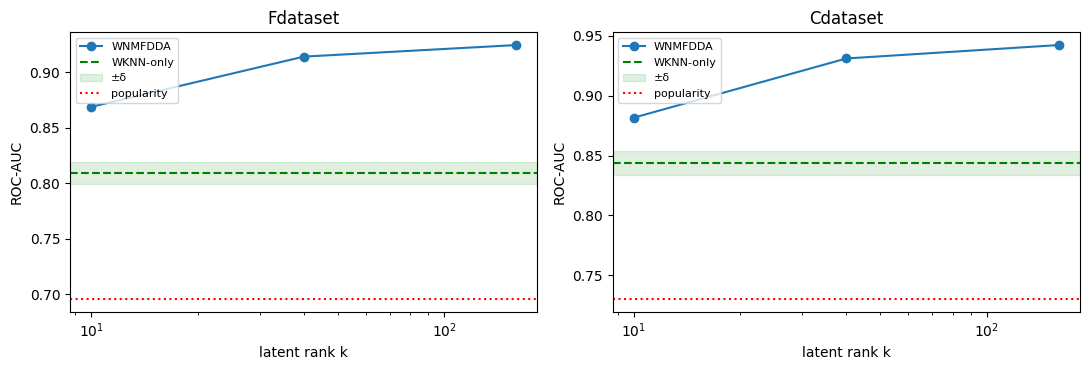

[Fdataset] effective rank of Y' (full data): 90% energy at k=91, 95% at k=126, 99% at k=189  (paper uses k=160; diagnostic only, not proof of redundancy)
[Cdataset] effective rank of Y' (full data): 90% energy at k=97, 95% at k=139, 99% at k=212  (paper uses k=160; diagnostic only, not proof of redundancy)


In [23]:
R2_CONDS = {c: CONDS[c] for c in ["POP", "WKNN_ONLY", "W1G1_k10", "W1G1_k40", "W1G1"]}
for ds, D in LOADED.items():
    print(f"Running R2 grid on {ds} ...")
    run_grid(D, R2_CONDS, SEEDS)

PAIRS = [("W1G1", "WKNN_ONLY"), ("W1G1", "POP"), ("W1G1_k10", "W1G1"), ("W1G1_k40", "W1G1"), ("W1G1_k40", "WKNN_ONLY"), ("W1G1_k10", "WKNN_ONLY")]
for ds, D in LOADED.items():
    print("=" * 100); print(f"R2 | {ds}")
    perf = pd.concat({m: seedmeans(ds, m, list(R2_CONDS)).mean() for m in METRICS}, axis=1)
    sd_ = seedmeans(ds, "auc", list(R2_CONDS)).std(ddof=1).rename("auc_sd_over_seeds")
    sub = RES[(RES.dataset == ds) & RES.cond.isin(list(R2_CONDS))]
    cost = sub.groupby("cond").agg(sec_per_fit=("time_s", "mean"), mean_iters=("n_iter", "mean"))
    kmap = {"POP": 0, "WKNN_ONLY": 0, "W1G1_k10": 10, "W1G1_k40": 40, "W1G1": PAPER["k"]}
    cost["factor_MB"] = [kmap[c] * (D.n + D.m) * 8 / 1e6 if kmap[c] else D.n * D.m * 8 / 1e6 * (c == "WKNN_ONLY") for c in cost.index]
    display(perf.join(sd_).join(cost).loc[list(R2_CONDS)].round(4))
    for m in METRICS:
        out = []
        for a_, b_ in PAIRS:
            T = seedmeans(ds, m, [a_, b_])
            row, st = stat_row(f"{a_} - {b_}", T[a_] - T[b_], delta=DELTA if m == "auc" else None)
            out.append(row)
            if m == "auc" and (a_, b_) == ("W1G1", "WKNN_ONLY"):
                PRIMARY[("R2", ds)] = dict(test="TOST equivalence AUC(k=160) vs WKNN-only, delta=0.01", stat=st["mean"], p=st["p_tost"],
                                           meaning="small p => equivalence established (supports R2)")
                VERDICT[("R2", ds)] = advantage_verdict(st)
                DETAIL[("R2", ds)] = f"AUC(WNMFDDA)-AUC(WKNN-only)={st['mean']:+.4f} CI[{st['ci_lo']:+.4f},{st['ci_hi']:+.4f}], TOST p={st['p_tost']:.3g}"
        print(f"\n-- paired differences on {m} --"); display(pd.DataFrame(out).set_index("contrast").round(4))
    print(f"R2 verdict [{ds}]: {VERDICT[('R2', ds)]}  |  {DETAIL[('R2', ds)]}")

# rank sweep plot + effective-rank diagnostic (diagnostic only)
fig, axs = plt.subplots(1, len(LOADED), figsize=(11, 3.8), squeeze=False)
for ax, ds in zip(axs[0], LOADED):
    ks = [10, 40, PAPER["k"]]; names = ["W1G1_k10", "W1G1_k40", "W1G1"]
    T = seedmeans(ds, "auc", names + ["WKNN_ONLY", "POP"])
    ax.plot(ks, T[names].mean().values, "o-", label="WNMFDDA"); ax.axhline(T["WKNN_ONLY"].mean(), ls="--", c="g", label="WKNN-only")
    ax.axhspan(T["WKNN_ONLY"].mean() - DELTA, T["WKNN_ONLY"].mean() + DELTA, color="g", alpha=0.12, label="±δ")
    ax.axhline(T["POP"].mean(), ls=":", c="r", label="popularity"); ax.set_xscale("log"); ax.set_xlabel("latent rank k"); ax.set_ylabel("ROC-AUC")
    ax.set_title(ds); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

for ds, D in LOADED.items():
    s = np.linalg.svd(wknn_reconstruct(D.Y, D)[0], compute_uv=False); e = np.cumsum(s ** 2) / (s ** 2).sum()
    print(f"[{ds}] effective rank of Y' (full data): 90% energy at k={int(np.searchsorted(e,0.90))+1}, 95% at k={int(np.searchsorted(e,0.95))+1}, "
          f"99% at k={int(np.searchsorted(e,0.99))+1}  (paper uses k={PAPER['k']}; diagnostic only, not proof of redundancy)")

---
# R3 — Does the graph-smoothness assumption match the association data?

> *The assumption that similarity-connected drugs or diseases should have similar association profiles may be violated or provide limited predictive benefit, so graph regularization may oversmooth meaningful biological differences.*

### E — Equations
For a symmetric non-negative graph $S^*$ with Laplacian $L=D-S^*$ and a binary profile $y$:
$$y^\top L y=\tfrac12\sum_{i,j}S^*_{ij}(y_i-y_j)^2 ,\qquad \mathbb{E}[y^\top L y]=\frac{2Wq(n-q)}{n(n-1)},\; W=\sum_{i<j}S^*_{ij},$$
under uniformly random assignments of exactly $q$ positives (degree-independent null). Profiles on the **drug graph** are the disease columns of $Y$; profiles on the **disease graph** are the drug rows.

### P — Proposition
If observed profiles are no smoother on the graph than prevalence-preserving random labels, the data give limited support for the smoothness assumption; this alone does not prove that regularization harms prediction.

### Q — Quantifiable prediction
* $\rho=\text{observed energy}/\text{expected energy}$ (aggregate over profiles, plus per-profile distribution), one-sided permutation p-value (column-wise permutations, $q$ preserved).
* Predictive effect of graph on/off ($\lambda=1$ vs $0$) with and without WKNN, and a $\lambda$ sensitivity sweep (no selection of $\lambda$ on test folds).

Decision rule: smoothness "holds" if $\rho<1$ **and** permutation $p<0.05$ on both sides. R3 is **SUPPORTED** when smoothness does *not* hold **and** the graph's AUC advantage is practically below δ (or negative); **WEAKENED** when smoothness holds **and** the graph's advantage exceeds δ; otherwise **MIXED/INCONCLUSIVE**. Primary test for Holm: larger of the two one-sided permutation p-values (small p ⇒ smooth ⇒ weakens R3).

### V — Verification
Check graph symmetry / non-negativity / PSD, validate the expectation formula against the empirical null mean, run the permutation test, then the graph ablation.

### L — Interpretation
$\rho\approx1$ or above together with no/negative graph benefit strengthens R3; $\rho\ll1$ with a held-out improvement weakens it.

,dataset,graph,profiles,min_eig_L,formula_vs_null_mean,rho_total,z,p_smoother,rho_total_q_ge2,p_smoother_q_ge2,median_rho,frac_profiles_rho_lt1,frac_profiles_sig_p05,spearman_graph_degree_vs_prevalence
0,Fdataset,drug graph (profiles = disease columns),313,0.0,1.0002,0.8422,-12.6990,0.001,0.8387,0.001,0.8563,0.6230,0.1789,0.0067
1,Fdataset,disease graph (profiles = drug rows),593,0.0,0.9994,0.8026,-17.6323,0.001,0.7870,0.001,0.7808,0.7622,0.2462,-0.0129
2,Cdataset,drug graph (profiles = disease columns),409,-0.0,1.0002,0.8409,-15.9822,0.001,0.8421,0.001,0.8446,0.6406,0.2054,0.0820
3,Cdataset,disease graph (profiles = drug rows),663,0.0,1.0001,0.6559,-32.8790,0.001,0.6428,0.001,0.6577,0.8808,0.3303,-0.0409


Checks: min_eig_L >= ~0 (PSD); formula_vs_null_mean ≈ 1 validates the expectation formula; a positive degree-prevalence correlation would inflate energy relative to the degree-independent null (conservative against smoothness).


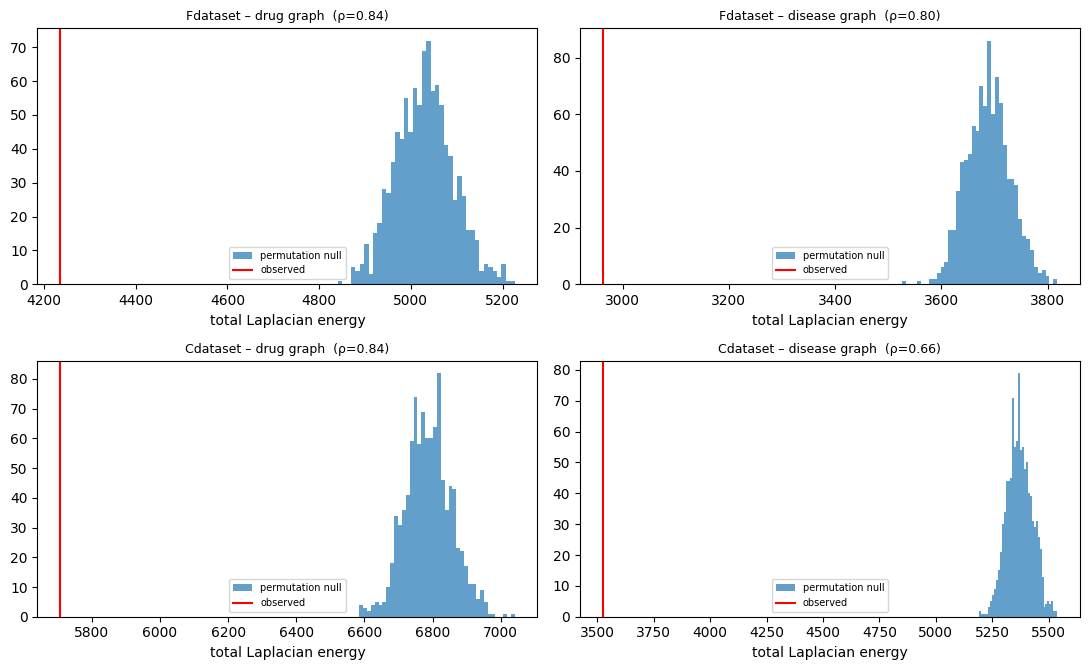

In [24]:
# ---- V1: graph validity + permutation test of Laplacian energy ----
def laplacian_energy_test(Sg, Pmat, n_perm, seed=0):
    n = Sg.shape[0]
    assert np.allclose(Sg, Sg.T) and (Sg >= 0).all(), "graph must be symmetric and non-negative"
    L = sps.csr_matrix(np.diag(Sg.sum(1)) - Sg)
    eig_min = np.linalg.eigvalsh(np.diag(Sg.sum(1)) - Sg).min()
    q = Pmat.sum(0); keep = (q > 0) & (q < n)
    P = Pmat[:, keep].astype(float); q = q[keep]
    Wtot = Sg.sum() / 2.0
    obs = (P * (L @ P)).sum(0)
    exp = 2 * Wtot * q * (n - q) / (n * (n - 1))
    rng = np.random.default_rng(seed); null = np.empty((n_perm, P.shape[1]), np.float32)
    for b in range(n_perm):
        Pp = rng.permuted(P, axis=0)                      # each profile permuted independently, q preserved
        null[b] = (Pp * (L @ Pp)).sum(0)
    tot_null = null.sum(1); T = obs.sum()
    def agg(mask):
        tn = null[:, mask].sum(1); To = obs[mask].sum()
        return dict(rho=To / exp[mask].sum(), z=(To - tn.mean()) / tn.std(ddof=1),
                    p_smoother=(1 + (tn <= To).sum()) / (n_perm + 1), p_rougher=(1 + (tn >= To).sum()) / (n_perm + 1))
    allq, q2 = agg(np.ones_like(q, bool)), agg(q >= 2)
    p_prof = (1 + (null <= obs[None, :]).sum(0)) / (n_perm + 1)
    return dict(psd_min_eig=eig_min, formula_check=tot_null.mean() / exp.sum(), n_profiles=int(keep.sum()),
                all=allq, q_ge2=q2, rho_median=float(np.median(obs / exp)), frac_rho_lt1=float(np.mean(obs < exp)),
                frac_sig_smoother=float(np.mean(p_prof < 0.05)), rho_prof=obs / exp, tot_null=tot_null, T_obs=T,
                spearman_deg_prev=stats.spearmanr(Sg.sum(1), Pmat.sum(1))[0])

R3 = {}
for ds, D in LOADED.items():
    for side, Sg, Pm in (("drug graph (profiles = disease columns)", D.SgR, D.Y), ("disease graph (profiles = drug rows)", D.SgD, D.Y.T)):
        R3[(ds, side)] = laplacian_energy_test(Sg, Pm, N_PERM, seed=1)
rows = []
for (ds, side), r in R3.items():
    rows.append(dict(dataset=ds, graph=side, profiles=r["n_profiles"], min_eig_L=r["psd_min_eig"], formula_vs_null_mean=r["formula_check"],
                     rho_total=r["all"]["rho"], z=r["all"]["z"], p_smoother=r["all"]["p_smoother"], rho_total_q_ge2=r["q_ge2"]["rho"],
                     p_smoother_q_ge2=r["q_ge2"]["p_smoother"], median_rho=r["rho_median"], frac_profiles_rho_lt1=r["frac_rho_lt1"],
                     frac_profiles_sig_p05=r["frac_sig_smoother"], spearman_graph_degree_vs_prevalence=r["spearman_deg_prev"]))
display(pd.DataFrame(rows).round(4))
print("Checks: min_eig_L >= ~0 (PSD); formula_vs_null_mean ≈ 1 validates the expectation formula; "
      "a positive degree-prevalence correlation would inflate energy relative to the degree-independent null (conservative against smoothness).")

fig, axs = plt.subplots(len(LOADED), 2, figsize=(11, 3.4 * len(LOADED)), squeeze=False)
for i, ds in enumerate(LOADED):
    for j, (key, r) in enumerate([kv for kv in R3.items() if kv[0][0] == ds]):
        ax = axs[i, j]; ax.hist(r[1]["tot_null"] if False else r["tot_null"], bins=40, alpha=0.7, label="permutation null")
        ax.axvline(r["T_obs"], c="r", label="observed"); ax.set_title(f"{ds} – {key[1].split(' (')[0]}  (ρ={r['all']['rho']:.2f})", fontsize=9)
        ax.set_xlabel("total Laplacian energy"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

for ds in LOADED:
    pd_, pi_ = [R3[k]["all"]["p_smoother"] for k in R3 if k[0] == ds]
    PRIMARY[("R3", ds)] = dict(test="max of one-sided permutation p (observed energy < null), drug & disease graphs",
                               stat=np.mean([R3[k]["all"]["rho"] for k in R3 if k[0] == ds]), p=max(pd_, pi_),
                               meaning="small p => data ARE smooth on graph (weakens R3)")

Running R3 grid on Fdataset ...
  [Fdataset] seed 0 done (20 new rows, 46s)
  [Fdataset] seed 1 done (40 new rows, 93s)
  [Fdataset] seed 2 done (60 new rows, 139s)
Running R3 grid on Cdataset ...
  [Cdataset] seed 0 done (20 new rows, 59s)
  [Cdataset] seed 1 done (40 new rows, 119s)
  [Cdataset] seed 2 done (60 new rows, 178s)
R3 graph ablation | Fdataset


,n_seeds,mean,ci95_lo,ci95_hi,boot_lo,boot_hi,worst_seed,best_seed,p
contrast,,,,,,,,,
[auc] graph on - off (WKNN off),5,0.1114,0.1070,0.1158,0.1087,0.1141,0.1080,0.1160,0.0
[auc] graph on - off (WKNN on),5,0.0257,0.0231,0.0283,0.0240,0.0272,0.0225,0.0277,0.0
[aupr] graph on - off (WKNN off),5,0.2248,0.2193,0.2303,0.2215,0.2284,0.2202,0.2310,0.0
[aupr] graph on - off (WKNN on),5,0.1302,0.1184,0.1419,0.1221,0.1372,0.1158,0.1420,0.0
[rec10] graph on - off (WKNN off),5,0.1954,0.1855,0.2054,0.1893,0.2019,0.1883,0.2064,0.0
[rec10] graph on - off (WKNN on),5,0.1018,0.0933,0.1103,0.0972,0.1074,0.0957,0.1128,0.0


R3 verdict [Fdataset]: WEAKENED (smooth AND graph benefit > delta)  |  smooth_on_both_sides=True; AUC(graph on - off | WKNN on)=+0.0257 CI[+0.0231,+0.0283]

λ sensitivity, mean ROC-AUC over 3 seeds:


,λ=0.0,λ=0.1,λ=1.0,λ=10.0
WKNN off,0.8088,0.9058,0.9206,0.8191
WKNN on,0.8990,0.9098,0.9243,0.8442


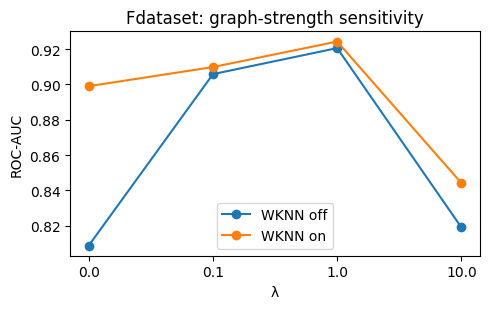

R3 graph ablation | Cdataset


,n_seeds,mean,ci95_lo,ci95_hi,boot_lo,boot_hi,worst_seed,best_seed,p
contrast,,,,,,,,,
[auc] graph on - off (WKNN off),5,0.0981,0.0951,0.1011,0.0964,0.1002,0.0963,0.1017,0.0
[auc] graph on - off (WKNN on),5,0.0179,0.0152,0.0206,0.0161,0.0194,0.0146,0.0200,0.0
[aupr] graph on - off (WKNN off),5,0.3061,0.2947,0.3174,0.3002,0.3142,0.2987,0.3215,0.0
[aupr] graph on - off (WKNN on),5,0.1776,0.1707,0.1844,0.1735,0.1825,0.1709,0.1862,0.0
[rec10] graph on - off (WKNN off),5,0.2020,0.1867,0.2173,0.1909,0.2089,0.1805,0.2113,0.0
[rec10] graph on - off (WKNN on),5,0.0770,0.0667,0.0873,0.0709,0.0831,0.0668,0.0881,0.0


R3 verdict [Cdataset]: WEAKENED (smooth AND graph benefit > delta)  |  smooth_on_both_sides=True; AUC(graph on - off | WKNN on)=+0.0179 CI[+0.0152,+0.0206]

λ sensitivity, mean ROC-AUC over 3 seeds:


,λ=0.0,λ=0.1,λ=1.0,λ=10.0
WKNN off,0.8424,0.9276,0.9398,0.8499
WKNN on,0.9256,0.9356,0.9433,0.8720


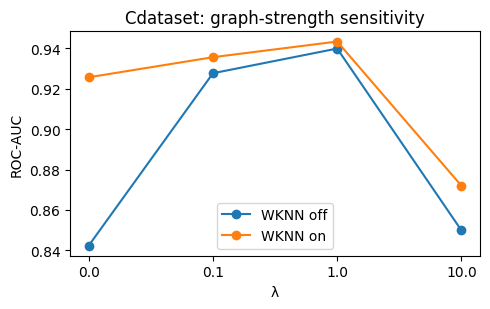

In [25]:
# ---- V2/L: predictive effect of the graph (ablation) and lambda sensitivity ----
R3_CONDS = {c: CONDS[c] for c in ["W0G0", "W1G0", "W0G1", "W1G1"]}
for w in (0, 1):
    for lam in LAMS:
        R3_CONDS[lam_name(w, lam)] = CONDS[lam_name(w, lam)]
for ds, D in LOADED.items():
    print(f"Running R3 grid on {ds} ...")
    run_grid(D, {c: R3_CONDS[c] for c in ["W0G0", "W1G0", "W0G1", "W1G1"]}, SEEDS)                       # reused from R1 if cached
    run_grid(D, {c: v for c, v in R3_CONDS.items() if "lam" in c}, SENS_SEEDS)                              # extra lambda values

for ds in LOADED:
    print("=" * 100); print(f"R3 graph ablation | {ds}")
    out = []
    for m in ["auc", "aupr", "rec10"]:
        for w, (a_, b_) in enumerate([("W0G1", "W0G0"), ("W1G1", "W1G0")]):
            T = seedmeans(ds, m, [a_, b_]); row, st = stat_row(f"[{m}] graph on - off ({'WKNN on' if w else 'WKNN off'})", T[a_] - T[b_]); out.append(row)
            if m == "auc" and w == 1:
                gst = st
    display(pd.DataFrame(out).set_index("contrast").round(4))
    smooth = all(R3[k]["all"]["rho"] < 1 and R3[k]["all"]["p_smoother"] < ALPHA for k in R3 if k[0] == ds)
    adv = advantage_verdict(gst)
    if (not smooth) and adv.startswith("SUPPORTED"):
        VERDICT[("R3", ds)] = "SUPPORTED (not smoother than random AND graph benefit < delta)"
    elif smooth and adv.startswith("WEAKENED"):
        VERDICT[("R3", ds)] = "WEAKENED (smooth AND graph benefit > delta)"
    else:
        VERDICT[("R3", ds)] = f"MIXED/INCONCLUSIVE (smooth={smooth}; graph advantage: {adv})"
    DETAIL[("R3", ds)] = f"smooth_on_both_sides={smooth}; AUC(graph on - off | WKNN on)={gst['mean']:+.4f} CI[{gst['ci_lo']:+.4f},{gst['ci_hi']:+.4f}]"
    print(f"R3 verdict [{ds}]: {VERDICT[('R3', ds)]}  |  {DETAIL[('R3', ds)]}")

    # lambda sensitivity (first SENS seeds only; reported, never used to pick a test-set winner)
    tab = {}
    for w in (0, 1):
        tab[f"WKNN {'on' if w else 'off'}"] = {lam: seedmeans(ds, "auc", [lam_name(w, lam)], SENS_SEEDS).iloc[:, 0].mean() for lam in LAMS}
    sens = pd.DataFrame(tab).T; sens.columns = [f"λ={l}" for l in LAMS]
    print(f"\nλ sensitivity, mean ROC-AUC over {len(SENS_SEEDS)} seeds:"); display(sens.round(4))
    plt.figure(figsize=(5, 3.2))
    for r_ in sens.index:
        plt.plot(range(len(LAMS)), sens.loc[r_].values, "o-", label=r_)
    plt.xticks(range(len(LAMS)), [str(l) for l in LAMS]); plt.xlabel("λ"); plt.ylabel("ROC-AUC"); plt.title(f"{ds}: graph-strength sensitivity"); plt.legend(); plt.tight_layout(); plt.show()

---
# Consolidated evidence: Holm-corrected primary tests and verdicts
Six primary tests (R1, R2, R3 × Fdataset, Cdataset) are corrected jointly with Holm. **Note the direction of each test** (last column).

In [26]:
keys = [(h, ds) for h in ("R1", "R2", "R3") for ds in LOADED if (h, ds) in PRIMARY]
praw = [PRIMARY[k]["p"] for k in keys]
tab = pd.DataFrame([dict(hypothesis=h, dataset=ds, test=PRIMARY[(h, ds)]["test"], statistic=PRIMARY[(h, ds)]["stat"],
                         p_raw=PRIMARY[(h, ds)]["p"], what_small_p_means=PRIMARY[(h, ds)]["meaning"]) for h, ds in keys])
tab["p_holm"] = holm(praw, m=6)
display(tab[["hypothesis", "dataset", "test", "statistic", "p_raw", "p_holm", "what_small_p_means"]].round(4))

summ = pd.DataFrame([dict(hypothesis=h, dataset=ds, verdict=VERDICT.get((h, ds), "not run"), evidence=DETAIL.get((h, ds), "")) for h, ds in keys])
pd.set_option("display.max_colwidth", 200); display(summ)

tab.to_csv(os.path.join(OUT_DIR, f"primary_tests_holm_{PROFILE}.csv"), index=False)
summ.to_csv(os.path.join(OUT_DIR, f"verdicts_{PROFILE}.csv"), index=False)
print("saved:", RES_PATH, "| primary_tests_holm_*.csv | verdicts_*.csv  (in", OUT_DIR + ")")
print(f"Settings: profile={PROFILE}, seeds={N_SEEDS}, folds={N_FOLDS}, max_iter={MAX_ITER}, delta={DELTA}. "
      "Inference is conditional on these datasets (seed-to-seed variation = split/initialisation randomness). "
      "Negatives are unobserved pairs, so AUPR/AUC are lower-bound style estimates.")

,hypothesis,dataset,test,statistic,p_raw,p_holm,what_small_p_means
0,R1,Fdataset,paired t: AUC interaction != 0,-0.0857,0.000,0.000,small p => components interact (weakens R1)
1,R1,Cdataset,paired t: AUC interaction != 0,-0.0802,0.000,0.000,small p => components interact (weakens R1)
2,R2,Fdataset,"TOST equivalence AUC(k=160) vs WKNN-only, delt...",0.1152,1.000,1.000,small p => equivalence established (supports R2)
3,R2,Cdataset,"TOST equivalence AUC(k=160) vs WKNN-only, delt...",0.0983,1.000,1.000,small p => equivalence established (supports R2)
4,R3,Fdataset,max of one-sided permutation p (observed energ...,0.8224,0.001,0.004,small p => data ARE smooth on graph (weakens R3)
5,R3,Cdataset,max of one-sided permutation p (observed energ...,0.7484,0.001,0.004,small p => data ARE smooth on graph (weakens R3)


,hypothesis,dataset,verdict,evidence
0,R1,Fdataset,SUPPORTED (advantage < delta),"interaction=-0.0857 CI[-0.0899,-0.0815]; full-vs-best-single(W0G1)=+0.0040 CI[+0.0028,+0.0052]"
1,R1,Cdataset,SUPPORTED (advantage < delta),"interaction=-0.0802 CI[-0.0826,-0.0778]; full-vs-best-single(W0G1)=+0.0032 CI[+0.0023,+0.0041]"
2,R2,Fdataset,WEAKENED (advantage > delta),"AUC(WNMFDDA)-AUC(WKNN-only)=+0.1152 CI[+0.1127,+0.1176], TOST p=1"
3,R2,Cdataset,WEAKENED (advantage > delta),"AUC(WNMFDDA)-AUC(WKNN-only)=+0.0983 CI[+0.0954,+0.1012], TOST p=1"
4,R3,Fdataset,WEAKENED (smooth AND graph benefit > delta),"smooth_on_both_sides=True; AUC(graph on - off | WKNN on)=+0.0257 CI[+0.0231,+0.0283]"
5,R3,Cdataset,WEAKENED (smooth AND graph benefit > delta),"smooth_on_both_sides=True; AUC(graph on - off | WKNN on)=+0.0179 CI[+0.0152,+0.0206]"


saved: /kaggle/working/wnmfdda_rejection_results_quick.csv | primary_tests_holm_*.csv | verdicts_*.csv  (in /kaggle/working)
Settings: profile=quick, seeds=5, folds=5, max_iter=150, delta=0.01. Inference is conditional on these datasets (seed-to-seed variation = split/initialisation randomness). Negatives are unobserved pairs, so AUPR/AUC are lower-bound style estimates.
